# Modelado de la duración de una partida de League of Legends

**Entrega 3 · Proyecto Integrador de Ciencia de Datos · UTN FRM · 2026**
Comisión 5K09 · Grupo 5K09-02

> **Pregunta del proyecto:** ¿Es posible predecir la duración de una partida de
> League of Legends a partir de las características de los jugadores, de los
> campeones de los equipos y las condiciones iniciales de la partida?

## Hoja de ruta

| Sección | Qué pasa | Qué deja |
|---|---|---|
| **0** | Qué cambió desde la Entrega 2 | las dos oraciones del minuto 0 |
| **1** | La corrección de la Entrega 2: diferencias entre equipos, por grupo de elo | la ficha H9 y su veredicto |
| **2** | El planteo: objetivo, métrica, piso y validación | `X`, `y`, la partición y el piso |
| **3** | Todo adentro de un pipeline | la receta completa, en un objeto |
| **4** | La comparación entre familias | la tabla con media y desvío |
| **5** | Las columnas que probamos | el número con y sin cada grupo de columnas |
| **6** | El ajuste | las curvas, las grillas y el elegido |
| **7** | Lo que probamos para que no prediga el centro | pesos por banda y curvas de elo, por validación cruzada |
| **8** | El test, una sola vez | el número que se informa |
| **9** | Dónde se equivoca | el tramo del objetivo donde más erra |
| **10** | En qué se apoya | coeficientes, permutación y el chequeo de fuga |
| **11** | Lo que no anduvo y lo que quedó inconcluso | la opción del minuto 5 y 10 |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import (GridSearchCV, KFold, cross_val_predict,
                                     cross_validate, train_test_split,
                                     validation_curve)
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# La semilla se define una vez y se pasa a todo lo que la acepte
SEMILLA = 42

# Los dos colores de la cátedra, y un tercero más claro para el tercer grupo
TEAL, LADRILLO, TEAL_CLARO = "#009086", "#B5402C", "#7fc7c2"

POS = ["top", "jng", "mid", "bot", "sup"]
EQUIPOS = ["t1", "t2"]

# El mismo CSV congelado de la Entrega 2: corre local o en Colab con la carpeta datos/ subida
CANDIDATAS = [Path("datos"), Path("../entrega-2/datos"), Path("notebooks/entrega-2/datos")]
carpeta = next(c for c in CANDIDATAS if c.is_dir())
CSV = sorted(carpeta.glob("lol_*.csv"))[-1]
df = pd.read_csv(CSV)
CSV.name

'lol_2026-09-06.csv'

In [2]:
# Los chequeos de siempre antes de modelar
pd.Series({"filas": len(df), "columnas": df.shape[1],
           "match_id único": df["match_id"].is_unique,
           "columnas enteras vacías": len(df.columns[df.isna().all()])})

filas                      19145
columnas                     137
match_id único              True
columnas enteras vacías        0
dtype: object

# Sección 0 · Qué cambió desde la Entrega 2

**El objetivo no cambió**: sigue siendo `game_duration_s`, en segundos, y el
problema sigue siendo de regresión. **Lo que cambió son las columnas**: por la
corrección de la Entrega 2 entran las diferencias entre los dos equipos que se
conocen antes de jugar, y todo el análisis —la hipótesis nueva y el modelo— se
lee además por grupo de elo.

# Sección 1 · La corrección de la Entrega 2: ¿importa cuán desparejos llegan los equipos?

En la Entrega 2 el docente marcó dos cosas. La primera: armar **columnas de
diferencias entre los dos equipos que se puedan calcular antes de la partida**
—por ejemplo, la diferencia de armadura total—, formular una hipótesis nueva de
esas diferencias contra la duración, y hacer cada análisis **por grupo de elo**:
Hierro–Oro, Platino–Diamante y Master–Challenger. La segunda, como plan B si la
primera no funciona: un dataset con el estado de la partida a los 5 y a los 10
minutos. Esta sección resuelve la primera; la segunda se discute en la Sección 11.

### Las veinte diferencias, todas conocidas antes de empezar

La diferencia se toma **en valor absoluto**. `t1` y `t2` son los `teamId` 100 y
200, que Riot asigna sin criterio (H3 de la Entrega 2), así que el signo de
`t1 − t2` no significa nada: una partida con el equipo fuerte de un lado y otra
con el equipo fuerte del otro son la misma partida. Lo que sí significa algo es
**cuánto** se separan los dos equipos, sin importar cuál está arriba.

Son veinte: los 17 agregados de equipo del esquema, y tres que hay que armar
promediando los cinco jugadores de cada lado —elo, winrate y maestría, esta
última en logaritmo aplicado por jugador antes de promediar, que es la forma que
midió H2—. La clase que las calcula es la misma que después entra al pipeline
del modelo, en la Sección 3: el número de la hipótesis y el del modelo salen del
mismo código.

In [3]:
# Los 17 agregados de equipo del esquema, y las columnas de jugador que se promedian por equipo
AGG = ["mains_count", "num_tanks", "num_mages", "num_assassins", "num_marksmen",
       "num_fighters", "num_supports", "avg_attack", "avg_defense", "avg_magic",
       "avg_difficulty", "avg_attackrange", "total_base_hp", "total_base_armor",
       "count_teleport", "count_ignite", "count_flash"]


def de_jugador(feature, equipos=EQUIPOS):
    """Los nombres de las columnas de una feature de jugador, para los equipos pedidos."""
    return [f"{e}_{p}_{feature}" for e in equipos for p in POS]


def por_equipo(X, equipo):
    """Elo, winrate y log-maestría medios de los cinco jugadores de un equipo."""
    return pd.DataFrame({
        "elo": X[de_jugador("player_elo", [equipo])].mean(axis=1),
        "winrate": X[de_jugador("player_winrate", [equipo])].mean(axis=1),
        "logmastery": np.log1p(X[de_jugador("champ_mastery_pts", [equipo])]).mean(axis=1)},
        index=X.index)


class DiferenciasEntreEquipos(BaseEstimator, TransformerMixin):
    """Cuánto se separan los dos equipos en cada columna conocida antes de jugar: |t1 - t2|."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        t1, t2 = por_equipo(X, "t1"), por_equipo(X, "t2")
        nuevas = {f"dif_{a}": (X[f"t1_{a}"] - X[f"t2_{a}"]).abs() for a in AGG}
        nuevas |= {f"dif_{k}": (t1[k] - t2[k]).abs() for k in t1.columns}
        return pd.DataFrame(nuevas, index=X.index)

    def get_feature_names_out(self, input_features=None):
        return np.array([f"dif_{a}" for a in AGG] + ["dif_elo", "dif_winrate", "dif_logmastery"])


DIFS = DiferenciasEntreEquipos().fit_transform(df)
DIFS.shape

(19145, 20)

In [4]:
# Que la transformación no rompió nada: sin nulos, sin negativos, una fila por partida
pd.Series({"filas": len(DIFS), "nulos": int(DIFS.isna().sum().sum()),
           "valores negativos": int((DIFS < 0).sum().sum()),
           "mismo índice que df": DIFS.index.equals(df.index)})

filas                  19145
nulos                      0
valores negativos          0
mismo índice que df     True
dtype: object

### Los tres grupos de elo

El elo de cada jugador es el proxy del pipeline, `TIER_BASE_MMR[tier] + bonus de
división + LP / 2`, y los cortes entre grupos salen de la misma tabla: Platino
arranca en 2.000 y Master en 2.900. **Esmeralda queda en el grupo del medio**,
porque en la escalera está entre Platino y Diamante. A cada partida se le asigna
el grupo de **el elo medio de sus diez jugadores**.

In [5]:
# El grupo de cada partida, según el elo medio de los diez jugadores
GRUPOS = ["Hierro–Oro", "Platino–Diamante", "Master–Challenger"]
CORTES_ELO = [-np.inf, 2000, 2900, np.inf]

elo_partida = df[de_jugador("player_elo")].mean(axis=1)
grupo = pd.cut(elo_partida, CORTES_ELO, right=False, labels=GRUPOS)

pd.DataFrame({"partidas": grupo.value_counts().reindex(GRUPOS),
              "proporción": grupo.value_counts(normalize=True).reindex(GRUPOS).round(3),
              "elo medio mínimo": elo_partida.groupby(grupo, observed=True).min().round(0),
              "elo medio máximo": elo_partida.groupby(grupo, observed=True).max().round(0),
              "duración mediana (s)": df["game_duration_s"].groupby(grupo, observed=True).median()})

,partidas,proporción,elo medio mínimo,elo medio máximo,duración mediana (s)
Hierro–Oro,6559,0.343,1016.0,1999.0,1821.0
Platino–Diamante,5609,0.293,2000.0,2900.0,1765.0
Master–Challenger,6977,0.364,2900.0,4918.0,1679.0


In [6]:
# Cuántas partidas tienen a los diez jugadores dentro del mismo grupo
grupo_jugador = df[de_jugador("player_elo")].apply(
    lambda c: pd.cut(c, CORTES_ELO, right=False, labels=GRUPOS))
pd.Series({"partidas con los 10 en el mismo grupo": (grupo_jugador.nunique(axis=1) == 1).mean(),
           "jugadores con el elo por defecto (1500 y 0,50)":
               ((df[de_jugador("player_elo")].to_numpy() == 1500)
                & (df[de_jugador("player_winrate")].to_numpy() == 0.50)).mean()}).round(3)

partidas con los 10 en el mismo grupo             0.404
jugadores con el elo por defecto (1500 y 0,50)    0.005
dtype: float64

Los tres grupos quedan parejos: **6.559 partidas en Hierro–Oro (34,3 %), 5.609 en
Platino–Diamante (29,3 %) y 6.977 en Master–Challenger (36,4 %)**. Ninguno es tan
chico como para que su análisis quede sostenido por un puñado de filas.

La duración mediana baja con el nivel: 1.821 segundos en Hierro–Oro, 1.765 en
Platino–Diamante y 1.679 en Master–Challenger, más de dos minutos entre
puntas. Es la misma tendencia que midió H4 en la Entrega 2, ahora leída por grupo.

Dos salvedades que conviene saber decir. Sólo el **40,4 %** de las partidas tiene
a los diez jugadores dentro del mismo grupo: el emparejamiento mezcla niveles
vecinos, así que el grupo es el de la partida, no el de cada jugador. Y el 0,5 %
de los lugares de jugador tiene el elo por defecto (1500, sin ranked): por
construcción, esos jugadores suman hacia Hierro–Oro.

### Las funciones del método, las mismas de la Entrega 2

In [7]:
# Las tres medidas de la cátedra y el semáforo, verbatim de la Entrega 2
def eta2(numerica, categoria):
    """Proporción de la varianza de la numérica que explica la categoría."""
    g = numerica.groupby(categoria)
    m = numerica.mean()
    return (g.count() * (g.mean() - m) ** 2).sum() / ((numerica - m) ** 2).sum()


def asociacion(x, y):
    """Pearson, Spearman y la brecha entre ambos."""
    p, s = x.corr(y), x.corr(y, method="spearman")
    return pd.Series({"pearson": p, "spearman": s, "brecha": s - p}).round(3)


CORTES = {"separacion": (0.2, 0.8), "eta2": (0.05, 0.25),
          "correlacion": (0.2, 0.6), "brecha": (0.05, 0.15)}


def semaforo(valor, medida):
    """Devuelve la zona en la que cae el valor, según la medida usada."""
    bajo, alto = CORTES[medida]
    v = abs(valor)
    return "rojo" if v < bajo else "verde" if v > alto else "amarillo"


dur = df["game_duration_s"]

### H9 · Cuanto más desparejos llegan los equipos, más corta es la partida

**Afirmación.** Cuando los dos equipos llegan muy distintos —uno con mucho más
elo, más maestría, o una composición mucho más tanque que la del otro—, el más
fuerte impone su ventaja temprano y cierra antes. Cuanto mayor la diferencia
entre los equipos, más corta la partida.

**Qué espero ver.** Correlaciones negativas entre cada diferencia y la duración.
La más fuerte debería ser la de elo, porque es la que mide directamente cuán
mejor juega un equipo que el otro; las de composición, más chicas.

**Por qué esta medida.** Es una asociación entre dos numéricas, así que van
Pearson y Spearman, con la brecha como detector de curvatura. Se mide primero
sobre las 19.145 partidas, y después **por grupo de elo**, que es el corte que
pidió el docente: si el efecto existiera escondido en un nivel de juego y
diluido en el total, aparecería ahí.

In [8]:
# Cada diferencia contra la duración, sobre todas las partidas
h9 = pd.DataFrame({c: asociacion(DIFS[c], dur) for c in DIFS}).T
h9["zona"] = h9["pearson"].map(lambda v: semaforo(v, "correlacion"))
h9["zona de la brecha"] = h9["brecha"].map(lambda v: semaforo(v, "brecha"))
h9.sort_values("pearson", key=abs, ascending=False)

,pearson,spearman,brecha,zona,zona de la brecha
dif_elo,-0.064,-0.064,0.000,rojo,rojo
dif_logmastery,-0.038,-0.031,0.008,rojo,rojo
dif_num_supports,0.030,0.028,-0.002,rojo,rojo
dif_winrate,-0.024,-0.006,0.018,rojo,rojo
dif_count_ignite,0.022,0.022,-0.000,rojo,rojo
dif_num_marksmen,0.020,0.022,0.002,rojo,rojo
dif_avg_defense,0.019,0.013,-0.006,rojo,rojo
dif_mains_count,-0.018,-0.016,0.002,rojo,rojo
dif_avg_attack,0.016,0.015,-0.001,rojo,rojo
dif_num_mages,0.013,0.015,0.002,rojo,rojo


In [9]:
# El resumen que decide
pd.Series({"|pearson| máximo": h9["pearson"].abs().max(),
           "la diferencia que lo alcanza": h9["pearson"].abs().idxmax(),
           "diferencias en rojo": int((h9["zona"] == "rojo").sum()),
           "de un total de": len(h9),
           "|brecha| máxima": h9["brecha"].abs().max()})

|pearson| máximo                  0.064
la diferencia que lo alcanza    dif_elo
diferencias en rojo                  20
de un total de                       20
|brecha| máxima                   0.018
dtype: object

**Resultado.** Las veinte diferencias caen en **rojo**. La más fuerte es la de
elo, con Pearson **−0,064**: tiene el signo que esperábamos y le falta casi todo
para llegar al corte de 0,2. Las de composición no pasan de 0,03, y
la que dio el docente como ejemplo, la armadura base, da **0,008**. La brecha
máxima entre Spearman y Pearson es 0,018, también roja, así que no hay ninguna
relación curva escondida detrás de un Pearson chico.

Con el método de la cátedra, un rojo termina la hipótesis. El corte por grupo de
elo que sigue **no es un movimiento para rescatarla**, porque insistir sobre un
rojo es cazar resultados. Es el análisis que pidió el docente, y funciona como
control: si el efecto existiera dentro de un nivel de juego y se diluyera en el
total, ahí aparecería.

In [10]:
# La misma correlación, partida por grupo de elo
h9_grupo = pd.DataFrame({g: DIFS[grupo == g].corrwith(dur[grupo == g]) for g in GRUPOS}).round(3)
h9_grupo["|máximo|"] = h9_grupo[GRUPOS].abs().max(axis=1)
h9_grupo.sort_values("|máximo|", ascending=False)

,Hierro–Oro,Platino–Diamante,Master–Challenger,|máximo|
dif_winrate,-0.100,-0.005,-0.017,0.100
dif_elo,-0.076,-0.036,-0.014,0.076
dif_logmastery,-0.049,-0.023,-0.042,0.049
dif_avg_defense,0.008,0.040,0.017,0.040
dif_num_supports,0.003,0.030,0.038,0.038
dif_mains_count,-0.028,-0.028,-0.036,0.036
dif_num_marksmen,0.032,0.025,0.015,0.032
dif_num_fighters,-0.005,-0.013,0.031,0.031
dif_avg_attack,0.019,-0.003,0.028,0.028
dif_count_teleport,0.001,0.026,0.002,0.026


In [11]:
# El resumen por grupo
pd.DataFrame({g: {"|pearson| máximo": h9_grupo[g].abs().max(),
                  "la diferencia que lo alcanza": h9_grupo[g].abs().idxmax(),
                  "zona": semaforo(h9_grupo[g].abs().max(), "correlacion")}
              for g in GRUPOS}).T

,|pearson| máximo,la diferencia que lo alcanza,zona
Hierro–Oro,0.1,dif_winrate,rojo
Platino–Diamante,0.04,dif_avg_defense,rojo
Master–Challenger,0.042,dif_logmastery,rojo


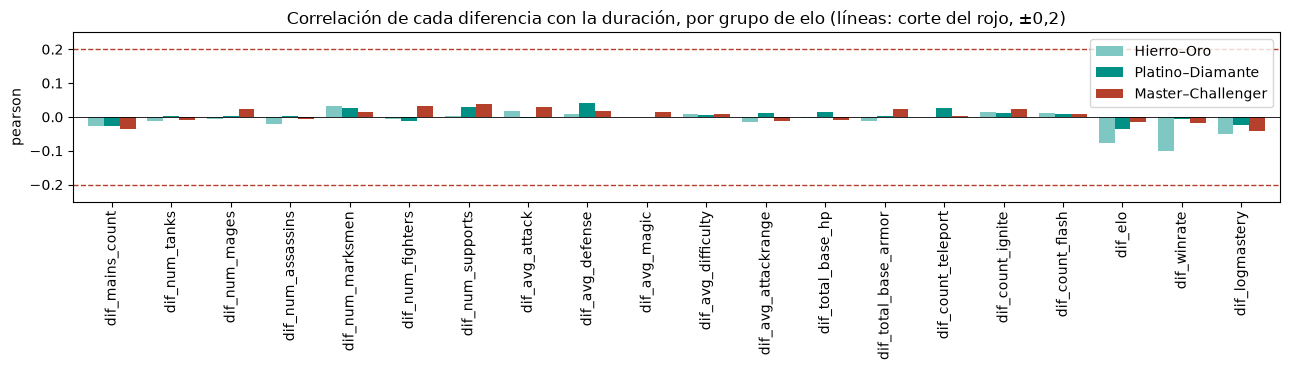

In [12]:
# Las veinte correlaciones de cada grupo, contra el corte del rojo
fig, ax = plt.subplots(figsize=(13, 3.8))
h9_grupo[GRUPOS].plot(kind="bar", ax=ax, color=[TEAL_CLARO, TEAL, LADRILLO], width=.8)
for corte in (0.2, -0.2):
    ax.axhline(corte, color=LADRILLO, linestyle="--", linewidth=1)
ax.axhline(0, color="black", linewidth=.6)
ax.set_title("Correlación de cada diferencia con la duración, por grupo de elo (líneas: corte del rojo, ±0,2)")
ax.set_ylabel("pearson")
ax.set_ylim(-0.25, 0.25)
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

**Resultado tras partir por grupo de elo.** Ningún grupo sale del rojo. El número
más alto de los sesenta es **−0,100**, la diferencia de winrate en Hierro–Oro: la
mitad del corte. En Platino–Diamante el máximo es 0,040, y en Master–Challenger,
0,042.

**Qué se ve.** Las barras de los tres grupos oscilan alrededor de cero sin un
patrón común, y ninguna se acerca a las líneas de ±0,2. El único rastro de orden
es la diferencia de elo, que se debilita a medida que sube el nivel: −0,076,
−0,036 y −0,014. En el nivel bajo el desbalance pesa un poco más, siempre en rojo.

**Qué hago con eso. Hipótesis refutada, en total y en los tres grupos.** Que los
equipos lleguen desparejos no dice cuánto va a durar la partida. Igual, las
veinte diferencias entran al modelo de la Sección 3 como un bloque que se puede
apagar: un modelo las ve todas juntas y podría encontrar en la combinación lo que
ninguna muestra sola. La Sección 5 lo mide. Y el rojo deja en pie el plan B del
docente, el dataset al minuto 5 y al 10, que se discute en la Sección 11.

# Sección 2 · El planteo: qué se predice, con qué se mide y contra qué se compara

Antes del primer modelo, las cuatro decisiones de la consigna: la métrica, el
piso, cómo se arman los pedazos de la validación, y que todo vaya adentro de un
pipeline. Las tres primeras se toman acá; la cuarta es la Sección 3.

### La métrica: el MAE, en segundos

Se predice `game_duration_s`, un número: es regresión. La métrica declarada es el
**error absoluto medio (MAE)**, porque se lee en las unidades del objetivo
—«le erramos por tantos segundos en promedio»— y no necesita traducción para
defenderse. Trata igual un error de dos minutos en una partida de 15 que en una
de 40, y eso es lo que queremos: en este problema ningún tramo del objetivo es
más caro que otro. El R² se informa al lado como lectura secundaria, porque dice
qué fracción de la variación explica el modelo, y la Entrega 2 dejó una
expectativa concreta sobre ese número.

### La partición, con la semilla y estratificada por grupo de elo

El test es el 20 % de las partidas y se separa **una sola vez**, ahora. Se
estratifica por grupo de elo para que los tres grupos queden en el test con la
misma proporción que en el total: como el resultado se lee por grupo, ningún
grupo puede quedar con menos partidas de prueba que los otros por azar.

`X` son las 137 columnas crudas menos el objetivo. Todo lo que se derive de ellas
—sumas, promedios, diferencias, la plataforma— lo hace el pipeline.

In [13]:
# El objetivo, las columnas crudas, y la partición
y = df["game_duration_s"]
X = df.drop(columns=["game_duration_s"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=grupo, random_state=SEMILLA)
grupo_train, grupo_test = grupo.loc[X_train.index], grupo.loc[X_test.index]

pd.DataFrame({"train": grupo_train.value_counts(normalize=True),
              "test": grupo_test.value_counts(normalize=True)}).reindex(GRUPOS).round(3) \
  .assign(**{"partidas en test": grupo_test.value_counts().reindex(GRUPOS)})

,train,test,partidas en test
Hierro–Oro,0.343,0.343,1312
Platino–Diamante,0.293,0.293,1122
Master–Challenger,0.364,0.364,1395


### La validación: cinco pedazos al azar, y lo que eso supone

Todo lo que se elige —familia, hiperparámetros, columnas— se elige con
**validación cruzada de cinco pedazos sobre el entrenamiento**. El test no se
mira hasta la Sección 8.

Los pedazos se arman **al azar** (`KFold`), y la consigna obliga a decir por qué.
Una fila es una partida, y una partida no se repite: la clave es única. No hay
fecha en el dataset —la Entrega 2 lo verificó en su Sección 5—, así que no hay
forma de entrenar con lo anterior y validar con lo posterior. Lo que sí se repite
es algo que no está en las columnas: **el jugador semilla**. El DAG baja hasta 15
partidas de cada jugador que toma de la escalera, así que el mismo jugador puede
aparecer en varias filas, de los dos lados de un corte. El riesgo es que el
modelo reconozca a un jugador por su elo y su maestría y no aprenda nada general.
No se puede corregir con `GroupKFold` porque el identificador del jugador no
llegó al CSV; se declara, y se vigila en la Sección 8: si el número del test cae
mucho respecto del de la validación cruzada, ésta es la primera sospechosa.

In [14]:
# Los cinco pedazos del entrenamiento
cv = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
pd.DataFrame([{"entrena con": len(e), "valida sobre": len(v)} for e, v in cv.split(X_train)],
             index=[f"fold {i + 1}" for i in range(5)])

,entrena con,valida sobre
fold 1,12252,3064
fold 2,12253,3063
fold 3,12253,3063
fold 4,12253,3063
fold 5,12253,3063


### El piso: un modelo que no mira ninguna columna

`DummyRegressor` contesta siempre el mismo número, sin mirar la partida. Con el
MAE, la constante que menos erra es **la mediana** del entrenamiento, así que el
piso es `strategy="median"`. Se mide con la misma validación que todo lo demás,
y en total y por grupo.

# Sección 3 · Todo adentro de un pipeline

La consigna lo pide sin excepciones: imputar, escalar, codificar y las columnas
derivadas van **adentro** del objeto que se entrena. El pipeline tiene tres pasos:

1. **`derivar`** — de las 137 columnas crudas a las que dejó la tabla de
   candidatas de la Entrega 2, más las veinte diferencias de la Sección 1. Son dos
   transformadores propios unidos con `FeatureUnion`, y las diferencias se pueden
   apagar con `"drop"` para medir con y sin ellas.
2. **`preparar`** — las numéricas se imputan con la mediana y se escalan; la
   plataforma, la única categórica, se codifica en ceros y unos.
3. **`modelo`** — el último paso, el único que cambia entre familias.

### Lo que dejó la Entrega 2, como un transformador

La tabla de candidatas de la Entrega 2 decidió cómo entra cada columna, y este
transformador lo escribe:

- Los agregados de equipo entran como **suma `t1 + t2`** (H3), y quedan 12 de los
  17: `mains_count` sale por H2, `avg_defense` y `avg_magic` por H7,
  `total_base_armor` por H5 y `count_flash` por H8.
- El elo, **agregado por partida**: el promedio de los diez (H4). El winrate sale
  por redundante con el elo (H6).
- La maestría, **en logaritmo aplicado por jugador antes de promediar** (H2).
- La **plataforma**, que sale del prefijo de `match_id` y se conoce antes de
  jugar: η² 0,020, la categórica más asociada al objetivo de la Entrega 2.

Y lo que no entra, declarado: los diez `champ_id` —con 173 campeones cada uno,
η² ≤ 0,016 por posición, y ninguna composición repetida en 19.145 partidas, así
que no hay nada que aprender de la combinación—, los hechizos y las runas como
códigos, y `roles_inferidos`. La diferencia de `num_marksmen`, que la Entrega 2
admitía, ahora es una de las veinte del otro transformador.

In [15]:
# Los 12 agregados que quedan, sumados entre los dos equipos
SUMAS = ["num_tanks", "num_mages", "num_assassins", "num_marksmen", "num_fighters",
         "num_supports", "avg_attack", "avg_difficulty", "avg_attackrange",
         "total_base_hp", "count_teleport", "count_ignite"]


class ColumnasDePartida(BaseEstimator, TransformerMixin):
    """Las columnas por partida que dejó la tabla de candidatas de la Entrega 2.

    plataforma=False la saca, para medir cuánto aporta.
    """

    def __init__(self, plataforma=True):
        self.plataforma = plataforma

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        nuevas = pd.DataFrame({f"suma_{a}": X[f"t1_{a}"] + X[f"t2_{a}"] for a in SUMAS}, index=X.index)
        nuevas["elo_partida"] = X[de_jugador("player_elo")].mean(axis=1)
        nuevas["logmastery_partida"] = np.log1p(X[de_jugador("champ_mastery_pts")]).mean(axis=1)
        if self.plataforma:
            nuevas["plataforma"] = X["match_id"].str.split("_").str[0]
        return nuevas

    def get_feature_names_out(self, input_features=None):
        nombres = [f"suma_{a}" for a in SUMAS] + ["elo_partida", "logmastery_partida"]
        return np.array(nombres + (["plataforma"] if self.plataforma else []))

In [16]:
# La preparación: una rama para las numéricas y otra para la categórica
preparar = ColumnTransformer([
    ("numericas", Pipeline([("imputar", SimpleImputer(strategy="median")),
                            ("escalar", StandardScaler())]),
     make_column_selector(dtype_include="number")),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"),
     make_column_selector(dtype_exclude="number"))])


def armar(modelo, diferencias=True, plataforma=True):
    """El pipeline entero, con el modelo que se le pase al final."""
    derivar = FeatureUnion(
        [("partida", ColumnasDePartida(plataforma=plataforma)),
         ("diferencias", DiferenciasEntreEquipos() if diferencias else "drop")],
        verbose_feature_names_out=False).set_output(transform="pandas")
    return Pipeline([("derivar", derivar), ("preparar", clone(preparar)), ("modelo", modelo)])


armar(Ridge())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('derivar', ...), ('preparar', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('partida', ...), ('diferencias', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, default=TrueIf True, :meth:`get_feature_names_out` will prefix all feature nameswith the name of the transformer that generated that feature.If False, :meth:`get_feature_names_out` will not prefix any featurenames and will error if feature names are not unique... versionadded:: 1.5",False
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,plataforma,True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, a

In [17]:
# Qué le llega al modelo: cuántas columnas, de qué tipo, y que no haya nulos
derivadas = armar(Ridge())["derivar"].fit_transform(X_train)
preparadas = armar(Ridge())[:-1].fit_transform(X_train)
pd.Series({"columnas derivadas": derivadas.shape[1],
           "numéricas": derivadas.select_dtypes("number").shape[1],
           "categóricas": derivadas.select_dtypes(exclude="number").shape[1],
           "columnas que llegan al modelo": preparadas.shape[1],
           "nulos": int(derivadas.isna().sum().sum())})

columnas derivadas               35
numéricas                        34
categóricas                       1
columnas que llegan al modelo    40
nulos                             0
dtype: int64

Al modelo le llegan **35 columnas derivadas**: las 12 sumas, el elo y la
log-maestría de la partida, la plataforma y las 20 diferencias. Son 34 numéricas
y una categórica. Después del `OneHotEncoder` son 40, porque la plataforma se
abre en seis columnas, una por servidor. Cero nulos: el imputador está por
contrato, para que el pipeline no se rompa el día que llegue una partida con un
dato faltante.

In [18]:
# El piso, medido con la misma validación cruzada
def medir(pipeline, X=None, y=None):
    """MAE y R² por validación cruzada: media y desvío, y el MAE sobre lo que vio."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    r = cross_validate(pipeline, X, y, cv=cv, n_jobs=-1, return_train_score=True,
                       scoring={"mae": "neg_mean_absolute_error", "r2": "r2"})
    return {"MAE cv": -r["test_mae"].mean(), "desvío": r["test_mae"].std(),
            "MAE train": -r["train_mae"].mean(), "R² cv": r["test_r2"].mean(),
            "segundos por fold": r["fit_time"].mean()}


piso = armar(DummyRegressor(strategy="median"))
pd.Series(medir(piso)).round(3) + 0.0

MAE cv               328.423
desvío                 4.855
MAE train            328.408
R² cv                  0.000
segundos por fold      0.286
dtype: float64

In [19]:
# El piso por grupo: el error de cada partida, calculado por el fold que no la vio
def mae_por_grupo(real, prediccion, grupos):
    """El MAE de cada grupo de elo, y el total."""
    error = (real - prediccion).abs()
    return pd.concat([error.groupby(grupos, observed=True).mean().reindex(GRUPOS),
                      pd.Series({"total": error.mean()})])


pred_piso_cv = pd.Series(cross_val_predict(piso, X_train, y_train, cv=cv, n_jobs=-1), index=X_train.index)
piso_grupo = mae_por_grupo(y_train, pred_piso_cv, grupo_train)
piso_grupo.round(1)

Hierro–Oro           364.9
Platino–Diamante     309.0
Master–Challenger    309.7
total                328.4
dtype: float64

**El piso es 328,4 segundos, con un desvío de 4,9 entre pedazos.** Si a cada
partida le contestamos siempre la mediana, le erramos en promedio por cinco
minutos y medio. Es el número contra el que se lee todo lo que viene. Su R² es
cero, por definición.

Por grupo, el piso no es el mismo: **364,9 segundos en Hierro–Oro** contra 309,0 y
309,7 en los otros dos. Las partidas de nivel bajo tienen duraciones más
dispersas, así que adivinarlas cuesta más aunque no se haga nada. Por eso cada
grupo se compara contra su propio piso, y no contra el total.

# Sección 4 · La comparación: el simple primero, y tres familias más

El modelo simple es una **regresión lineal** con regularización (`Ridge`), con el
pipeline completo: es la referencia contra la que se justifica cualquier otro.
Contra ella van tres familias de árboles con sus valores por defecto —un árbol
solo, un bosque y un boosting—, sobre las mismas columnas y con los mismos cinco
pedazos. La columna de train va al lado para leer el sobreajuste.

In [20]:
# Las cuatro familias, cada una su propio pipeline
pipelines = {"regresión lineal (Ridge)": armar(Ridge()),
             "árbol de decisión": armar(DecisionTreeRegressor(random_state=SEMILLA)),
             "random forest": armar(RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEMILLA)),
             "gradient boosting": armar(HistGradientBoostingRegressor(random_state=SEMILLA))}

comparacion = {"piso (mediana)": medir(piso)}
for nombre, p in pipelines.items():
    comparacion[nombre] = medir(p)

tabla = pd.DataFrame(comparacion).T
tabla["brecha"] = tabla["MAE cv"] - tabla["MAE train"]
tabla["le gana al piso por"] = tabla.loc["piso (mediana)", "MAE cv"] - tabla["MAE cv"]
tabla.round(3) + 0.0

,MAE cv,desvío,MAE train,R² cv,segundos por fold,brecha,le gana al piso por
piso (mediana),328.423,4.855,328.408,0.000,0.162,0.016,0.000
regresión lineal (Ridge),319.447,4.474,318.334,0.051,0.159,1.112,8.977
árbol de decisión,467.802,5.414,0.000,-0.973,0.429,467.802,-139.379
random forest,321.021,3.858,118.569,0.039,32.020,202.452,7.402
gradient boosting,319.990,4.324,300.020,0.046,0.425,19.970,8.433


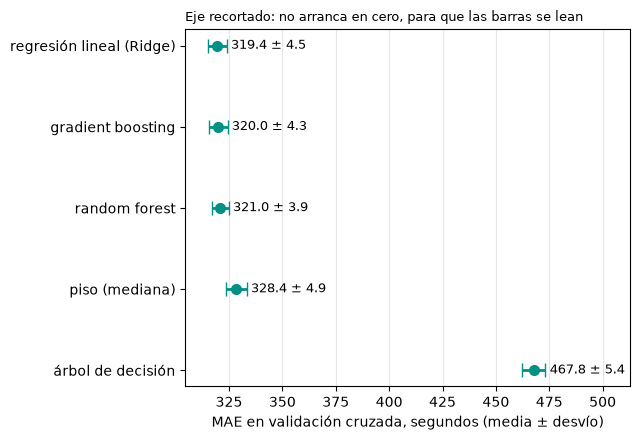

In [21]:
# La misma tabla, dibujada: el punto es la media y la barra, un desvío a cada lado
tabla_cv = tabla.sort_values("MAE cv", ascending=False)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.errorbar(tabla_cv["MAE cv"], tabla_cv.index, xerr=tabla_cv["desvío"], fmt="o", color=TEAL,
            ecolor=TEAL, elinewidth=2, capsize=5, markersize=7)
for nombre, fila in tabla_cv.iterrows():
    ax.text(fila["MAE cv"] + fila["desvío"] + 2, nombre, f"{fila['MAE cv']:.1f} ± {fila['desvío']:.1f}",
            va="center", ha="left", fontsize=9)
ax.set_xlabel("MAE en validación cruzada, segundos (media ± desvío)")
ax.set_title("Eje recortado: no arranca en cero, para que las barras se lean", fontsize=9, loc="left")
ax.set_xlim(tabla_cv["MAE cv"].min() - 15, tabla_cv["MAE cv"].max() + 45)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Tres lecturas en una tabla:

- **La regresión lineal es la mejor de las cuatro**: 319,4 ± 4,5 segundos, nueve
  menos que el piso. Nueve segundos son dos desvíos: **le gana al piso por más que
  el ruido, y por muy poco**. Su R² en validación es 0,051, o sea que explica el 5 %
  de la variación de la duración.
- **El árbol sin límite memoriza**: MAE de 0 en train y de 467,8 en validación,
  139 segundos **peor que el piso**. Cada partida del entrenamiento tiene su hoja,
  y eso no generaliza a nada.
- **El bosque y el boosting empatan con la lineal**: 321,0 ± 3,9 y 320,0 ± 4,3. Las
  barras se superponen, y la brecha entre train y validación —202 segundos el
  bosque, 20 el boosting, 1,1 la lineal— dice que lo que los árboles aprenden de
  más es ruido.

# Sección 5 · Las columnas que probamos: con y sin cada grupo

La ficha H9 midió las diferencias de a una. Un modelo las ve **todas juntas**, y
podría encontrar en la combinación algo que ninguna muestra sola. Se mide igual
que todo lo demás: el mismo pipeline con y sin las veinte diferencias, y con y
sin la plataforma, para la regresión lineal y para el mejor de los árboles.

In [22]:
# Cuatro variantes de columnas, para el simple y para el mejor árbol de la Sección 4
mejor_arbol = tabla.drop(index=["piso (mediana)", "regresión lineal (Ridge)"])["MAE cv"].idxmin()
VARIANTES = {"todas": (True, True), "sin diferencias": (False, True),
             "sin plataforma": (True, False), "sin ninguna de las dos": (False, False)}

variantes = {}
for familia in ["regresión lineal (Ridge)", mejor_arbol]:
    modelo = pipelines[familia]["modelo"]
    for variante, (difs, plat) in VARIANTES.items():
        variantes[(familia, variante)] = medir(armar(clone(modelo), diferencias=difs, plataforma=plat))

tabla_variantes = pd.DataFrame(variantes).T[["MAE cv", "desvío", "R² cv"]]
tabla_variantes.index.names = ["familia", "columnas"]
tabla_variantes["empeora sacándolas"] = (tabla_variantes["MAE cv"]
    - tabla_variantes.groupby(level="familia")["MAE cv"].transform("first"))
tabla_variantes.round(3)

MAE cv  desvío  R² cv  empeora sacándolas
familia                  columnas                                                          
regresión lineal (Ridge) todas                   319.447   4.474  0.051               0.000
                         sin diferencias         319.857   4.424  0.048               0.411
                         sin plataforma          320.420   4.680  0.044               0.974
                         sin ninguna de las dos  320.959   4.690  0.041               1.512
gradient boosting        todas                   319.990   4.324  0.046               0.000
                         sin diferencias         320.826   4.705  0.041               0.836
                         sin plataforma          320.139   4.384  0.045               0.149
                         sin ninguna de las dos  320.917   4.825  0.040               0.927

Las dos variantes se pueden leer en la misma tabla. Sacarle las veinte
diferencias a la lineal la empeora **0,4 segundos**; sacarle la plataforma, 1,0;
sacarle las dos, 1,5. Al boosting, 0,8, 0,1 y 0,9. **Todos esos números están por
debajo del desvío**, que en esta tabla ronda los 4,5 segundos, así que con la
regla de la cátedra ninguna de las dos es una diferencia.

Es el mismo veredicto de H9, ahora medido adentro del modelo: **las diferencias
entre equipos no sirvieron**, ni de a una ni todas juntas. Se quedan en el
pipeline porque se conocen antes de jugar y sacarlas no mejora nada, pero no se
pueden defender como una mejora. Y es una de las columnas «que probamos y no
anduvieron» que pide la consigna.

# Sección 6 · El ajuste: cuánto se mueve cada familia con sus hiperparámetros

La comparación de la Sección 4 usó los valores por defecto. Antes de elegir hay
que ver si el orden es de las familias o de los valores: un bosque mal
configurado puede perder contra una lineal bien configurada. Primero una curva
por familia, moviendo su hiperparámetro de complejidad; después una grilla chica
por familia, con `GridSearchCV` sobre el pipeline entero.

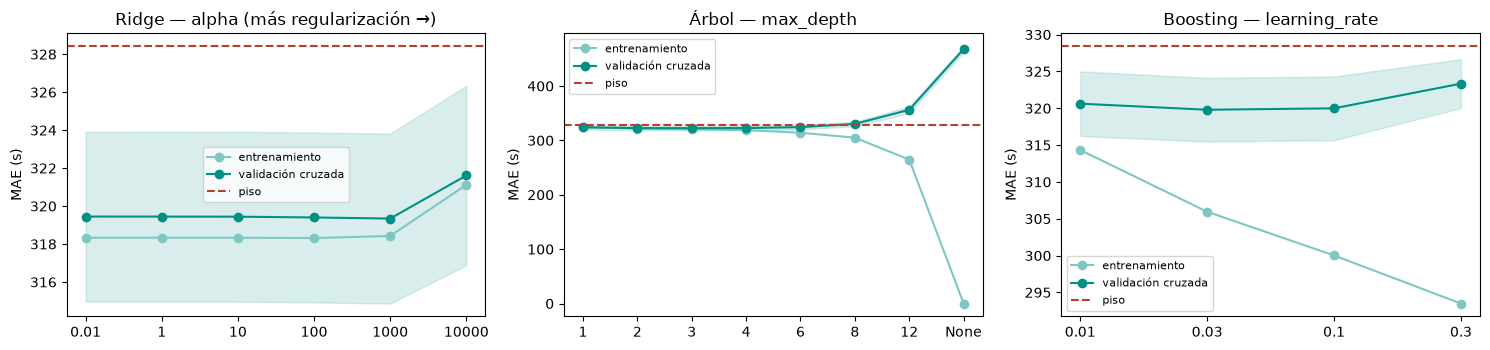

In [23]:
def curva(pipeline, parametro, valores, ax, titulo):
    """MAE en train y en validación cruzada para cada valor del hiperparámetro."""
    tr, va = validation_curve(pipeline, X_train, y_train, param_name=parametro, param_range=valores,
                              cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
    tr, va = -tr, -va
    etiquetas = [str(v) for v in valores]
    ax.plot(etiquetas, tr.mean(axis=1), marker="o", color=TEAL_CLARO, label="entrenamiento")
    ax.plot(etiquetas, va.mean(axis=1), marker="o", color=TEAL, label="validación cruzada")
    ax.fill_between(etiquetas, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1),
                    color=TEAL, alpha=0.15)
    ax.axhline(tabla.loc["piso (mediana)", "MAE cv"], color=LADRILLO, linestyle="--", label="piso")
    ax.set_title(titulo)
    ax.set_ylabel("MAE (s)")
    ax.legend(fontsize=8)
    return pd.DataFrame({"train": tr.mean(axis=1), "cv": va.mean(axis=1), "desvío cv": va.std(axis=1)},
                        index=etiquetas).round(1)


fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
curva_ridge = curva(pipelines["regresión lineal (Ridge)"], "modelo__alpha",
                    [0.01, 1, 10, 100, 1000, 10000], axes[0], "Ridge — alpha (más regularización →)")
curva_arbol = curva(pipelines["árbol de decisión"], "modelo__max_depth",
                    [1, 2, 3, 4, 6, 8, 12, None], axes[1], "Árbol — max_depth")
curva_boost = curva(pipelines["gradient boosting"], "modelo__learning_rate",
                    [0.01, 0.03, 0.1, 0.3], axes[2], "Boosting — learning_rate")
plt.tight_layout()
plt.show()

In [24]:
# Los números detrás de las tres curvas
pd.concat({"Ridge — alpha": curva_ridge, "árbol — max_depth": curva_arbol,
           "boosting — learning_rate": curva_boost})

train     cv  desvío cv
Ridge — alpha            0.01   318.3  319.4        4.5
                         1      318.3  319.4        4.5
                         10     318.3  319.4        4.5
                         100    318.3  319.4        4.5
                         1000   318.4  319.3        4.5
                         10000  321.1  321.6        4.7
árbol — max_depth        1      324.0  324.2        4.1
                         2      321.8  322.6        3.9
                         3      320.5  322.5        4.0
                         4      318.9  322.7        4.4
                         6      314.0  324.4        4.2
                         8      305.0  330.3        4.2
                         12     264.7  356.3        6.2
                         None     0.0  467.8        5.4
boosting — learning_rate 0.01   314.3  320.6        4.4
                         0.03   306.0  319.8        4.3
                         0.1    300.0  320.0        4.3
                         0.3    293.5  323.3        3.3

Las tres curvas cuentan lo mismo desde tres familias distintas:

- **Ridge** queda plana entre `alpha` 0,01 y 1.000 (319,4 → 319,3), y recién con
  10.000 empeora (321,6). Regularizar sirve cuando hay varianza para quitar, y acá
  no hay: la brecha entre train y validación es de un segundo.
- **El árbol** tiene su mejor punto en profundidad 2–3 (322,6 y 322,5). Desde 6 las
  curvas se separan: train sigue bajando y validación sube hasta 467,8 sin límite.
  Es el gráfico de sesgo y varianza de la teórica, con nuestros datos.
- **El boosting** mejora un poco bajando el `learning_rate` a 0,03 (319,8) y
  sobreajusta con 0,3 (293,5 en train y 323,3 en validación).

In [25]:
# Una grilla por familia, sobre el pipeline entero
GRILLAS = {
    "regresión lineal (Ridge)": {"modelo__alpha": [1, 10, 100, 1000]},
    "árbol de decisión":        {"modelo__max_depth": [3, 4, 6, 8],
                                 "modelo__min_samples_leaf": [1, 20, 100]},
    "random forest":            {"modelo__max_depth": [8, None],
                                 "modelo__min_samples_leaf": [5, 50],
                                 "modelo__max_features": [0.3, 1.0]},
    "gradient boosting":        {"modelo__learning_rate": [0.03, 0.1],
                                 "modelo__max_iter": [100, 300],
                                 "modelo__max_leaf_nodes": [7, 31]}}

pd.Series({n: int(np.prod([len(v) for v in g.values()])) * 5 for n, g in GRILLAS.items()},
          name="entrenamientos")

regresión lineal (Ridge)    20
árbol de decisión           60
random forest               40
gradient boosting           40
Name: entrenamientos, dtype: int64

In [26]:
# Las cuatro búsquedas; tarda unos minutos, casi todo en el bosque
busquedas = {}
for nombre, grilla in GRILLAS.items():
    p = pipelines[nombre]
    if nombre == "random forest":
        p = clone(p).set_params(modelo__n_estimators=200)
    busquedas[nombre] = GridSearchCV(p, grilla, cv=cv, scoring="neg_mean_absolute_error",
                                     n_jobs=-1, return_train_score=True).fit(X_train, y_train)

pd.DataFrame({n: {"por defecto (Sección 4)": tabla.loc[n, "MAE cv"],
                  "mejor de la grilla": -b.best_score_,
                  "desvío": b.cv_results_["std_test_score"][b.best_index_],
                  "MAE train": -b.cv_results_["mean_train_score"][b.best_index_]}
              for n, b in busquedas.items()}).T.round(1)

,por defecto (Sección 4),mejor de la grilla,desvío,MAE train
regresión lineal (Ridge),319.4,319.3,4.5,318.4
árbol de decisión,467.8,322.5,4.0,320.5
random forest,321.0,319.1,4.5,299.4
gradient boosting,320.0,319.1,4.3,312.6


In [27]:
# Con qué hiperparámetros llegó cada uno a su mejor
pd.DataFrame({n: {k.split("__")[-1]: v for k, v in b.best_params_.items()}
              for n, b in busquedas.items()}).T.fillna("")

,alpha,max_depth,min_samples_leaf,max_features,learning_rate,max_iter,max_leaf_nodes
regresión lineal (Ridge),1000.0,,,,,,
árbol de decisión,,3.0,1.0,,,,
random forest,,,50.0,1.0,,,
gradient boosting,,,,,0.1,100.0,7.0


In [28]:
# La regla de la cátedra, escrita: el complejo tiene que ganarle al simple por más que su desvío
simple = "regresión lineal (Ridge)"
mae_simple = -busquedas[simple].best_score_
retador = min(busquedas, key=lambda n: -busquedas[n].best_score_)
desvio_retador = busquedas[retador].cv_results_["std_test_score"][busquedas[retador].best_index_]
ventaja = mae_simple - (-busquedas[retador].best_score_)

elegido_nombre = retador if (retador != simple and ventaja > desvio_retador) else simple
elegido = busquedas[elegido_nombre].best_estimator_

pd.Series({"el mejor de las grillas": retador,
           "le saca al simple (s)": round(ventaja, 1),
           "su desvío (s)": round(desvio_retador, 1),
           "elegido": elegido_nombre})

el mejor de las grillas           gradient boosting
le saca al simple (s)                           0.3
su desvío (s)                                   4.3
elegido                    regresión lineal (Ridge)
dtype: object

In [29]:
# La tabla entera de la grilla del elegido, no sólo el ganador
def tabla_de(busqueda):
    """cv_results_ reducido a lo que se lee: hiperparámetros, MAE en validación y en train."""
    r = pd.DataFrame(busqueda.cv_results_)
    params = [c for c in r.columns if c.startswith("param_")]
    t = r[params].rename(columns=lambda c: c.split("__")[-1])
    t["MAE cv"] = -r["mean_test_score"]
    t["desvío"] = r["std_test_score"]
    t["MAE train"] = -r["mean_train_score"]
    return t.sort_values("MAE cv").round({"MAE cv": 1, "desvío": 1, "MAE train": 1})


tabla_de(busquedas[elegido_nombre])

,alpha,MAE cv,desvío,MAE train
3,1000,319.3,4.5,318.4
2,100,319.4,4.5,318.3
1,10,319.4,4.5,318.3
0,1,319.4,4.5,318.3


In [30]:
# Y la del retador más fuerte entre los árboles, para ver cuánto empate hay adentro
arbol_fuerte = min([n for n in busquedas if n != simple], key=lambda n: -busquedas[n].best_score_)
tabla_de(busquedas[arbol_fuerte]).head(8)

,learning_rate,max_iter,max_leaf_nodes,MAE cv,desvío,MAE train
6,0.10,300,7,319.1,4.3,312.6
4,0.10,100,7,319.1,4.3,312.6
2,0.03,300,7,319.2,4.3,314.3
0,0.03,100,7,319.4,4.1,316.3
3,0.03,300,31,319.8,4.3,305.7
1,0.03,100,31,319.8,4.3,306.0
5,0.10,100,31,320.0,4.3,300.0
7,0.10,300,31,320.0,4.3,300.0


**El ajuste movió a todos hacia el mismo lugar.** El árbol limitado a
profundidad 3 pasó de 467,8 a 322,5. El bosque, con hojas de al menos 50
partidas, de 321,0 a 319,1. El boosting, con hojas chicas (7 por árbol), de 320,0
a 319,1. La lineal casi no se movió: de 319,4 a 319,3. Las tres familias de
árboles mejoraron cuando se las restringió, que es lo mismo que decir cuando se
las acercó a un modelo simple.

**La decisión.** El mejor de las cuatro grillas es el boosting, y le saca a la
lineal **0,3 segundos**, con un desvío de 4,3. Es la decimocuarta parte de la
barra de error. Con la regla de la cátedra —el complejo tiene que ganarle al
simple por más que el desvío— **se queda la regresión lineal**, con `alpha=1000`.
Además es la que menos tarda, la única cuyos pesos se leen directamente, y la que
menos sobreajusta.

La tabla de la grilla del elegido confirma que el `alpha` no importa: las cuatro
combinaciones caen en una décima. La del boosting dice lo mismo de su familia:
las ocho combinaciones caen entre 319,1 y 320,0, con desvíos de 4,3. **Casi toda
la tabla es un empate.**

In [31]:
# El elegido por grupo de elo, todavía en validación cruzada: cuánto le gana al piso en cada uno
pred_cv = pd.Series(cross_val_predict(clone(elegido), X_train, y_train, cv=cv, n_jobs=-1),
                    index=X_train.index)
por_grupo_cv = pd.DataFrame({"piso": piso_grupo,
                             elegido_nombre: mae_por_grupo(y_train, pred_cv, grupo_train)})
por_grupo_cv["le gana al piso por (s)"] = por_grupo_cv["piso"] - por_grupo_cv[elegido_nombre]
por_grupo_cv["mejora relativa"] = por_grupo_cv["le gana al piso por (s)"] / por_grupo_cv["piso"]
por_grupo_cv.round(3)

,piso,regresión lineal (Ridge),le gana al piso por (s),mejora relativa
Hierro–Oro,364.889,354.957,9.933,0.027
Platino–Diamante,309.040,304.800,4.240,0.014
Master–Challenger,309.726,297.553,12.173,0.039
total,328.423,319.342,9.082,0.028


El modelo le gana al piso en los tres grupos, y no por igual: **12,2 segundos en
Master–Challenger (3,9 %)**, 9,9 en Hierro–Oro (2,7 %) y 4,2 en Platino–Diamante
(1,4 %). Donde más ayuda es en el nivel alto, que también es donde el elo se
mueve junto con la duración (Sección 10). En el grupo del medio la ganancia apenas
alcanza un desvío del total.

# Sección 7 · Lo que probamos para que el modelo no conteste siempre el centro

El modelo de la Sección 6 le gana al piso por nueve segundos, y tiene un rasgo que
salta en cuanto se miran sus predicciones: contesta casi siempre algo cerca de la
mediana. Antes de mirar el test probamos dos formas de sacarlo de ahí, con la
misma validación cruzada que todo lo demás:

1. **Castigarlo por contestar el centro**: que las partidas de las puntas pesen
   más en el entrenamiento. Es el `class_weight` de la Práctica 2 llevado a
   regresión.
2. **Darle la forma que una recta no puede dibujar**: el elo es la columna con
   más señal, y su relación con la duración podría no ser una recta. Si no lo es,
   unas curvas la dibujan.

Ninguna de las dos se elige mirando el test.

### 7.1 Castigar el centro: pesos por banda de duración

La regresión minimiza el error **sumado sobre las partidas**, y todas pesan lo
mismo. Como más de la mitad dura entre 25 y 35 minutos, la forma más barata de
bajar esa suma es contestar algo de ese tramo, aunque eso signifique no acertar
nunca una partida de 15 o de 45. El modelo no está fallando: hace exactamente lo
que se le pidió.

La palanca es la misma que `class_weight` en la Práctica 2. Cada partida del
entrenamiento recibe un peso **inverso a la frecuencia de su banda**, así que las
bandas chicas cuentan tanto como las grandes. La **fuerza** gradúa el castigo: 0
es sin pesos, 1 es el equivalente de `balanced`, y los valores del medio son
versiones suaves. Los pesos salen sólo de la `y` del entrenamiento y se usan
sólo para entrenar. El MAE se mide **sin pesar**, sobre las partidas tal como
vienen, que es lo que va a encontrar el modelo cuando se use.

In [32]:
# Las bandas de minutos de la Entrega 2, y el peso de cada una
BANDAS = [0, 20, 25, 30, 35, 40, 100]
ETIQUETAS = ["<20", "20-25", "25-30", "30-35", "35-40", "40+"]
banda_train = pd.cut(y_train / 60, bins=BANDAS, labels=ETIQUETAS)


def pesos(fuerza):
    """Peso de cada partida: inverso a la frecuencia de su banda, elevado a la fuerza (0 = sin pesos, 1 = balanced)."""
    frecuencia = banda_train.value_counts(normalize=True)
    peso = (1 / (len(ETIQUETAS) * frecuencia)) ** fuerza
    return banda_train.map(peso).astype(float).to_numpy()


pd.DataFrame({"partidas": banda_train.value_counts().reindex(ETIQUETAS),
              "peso con fuerza 1": pd.Series(pesos(1), index=X_train.index)
                                     .groupby(banda_train, observed=True).first()}).round(2)

,partidas,peso con fuerza 1
game_duration_s,,
<20,1555,1.64
20-25,2328,1.10
25-30,4596,0.56
30-35,3958,0.64
35-40,1963,1.30
40+,916,2.79


In [33]:
# El modelo elegido con cuatro fuerzas de castigo: el MAE total, cuánto se abren las predicciones y el MAE por banda
def medir_con_pesos(pipeline, fuerza):
    """MAE por validación cruzada (sin pesar), su desvío, el desvío de las predicciones y el MAE por banda."""
    params = {"modelo__sample_weight": pesos(fuerza)}
    r = cross_validate(pipeline, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error",
                       params=params, n_jobs=-1)
    pred = pd.Series(cross_val_predict(pipeline, X_train, y_train, cv=cv, params=params, n_jobs=-1),
                     index=X_train.index)
    fila = {"MAE cv": -r["test_score"].mean(), "desvío": r["test_score"].std(),
            "desvío de las predicciones": pred.std()}
    return fila | (y_train - pred).abs().groupby(banda_train, observed=True).mean().to_dict()


castigo = pd.DataFrame({f: medir_con_pesos(clone(elegido), f) for f in [0, 0.25, 0.5, 1.0]}).T
castigo.index.name = "fuerza"
castigo.round(1)

,MAE cv,desvío,desvío de las predicciones,<20,20-25,25-30,30-35,35-40,40+
fuerza,,,,,,,,,
0.00,319.3,4.5,90.1,755.2,338.3,120.4,185.9,453.9,817.9
0.25,319.4,4.4,102.9,757.4,340.4,128.6,182.2,444.3,805.2
0.50,320.0,4.3,117.2,762.2,345.5,139.3,177.5,431.2,788.8
1.00,324.0,4.2,149.7,781.7,366.5,169.2,167.5,393.3,742.8


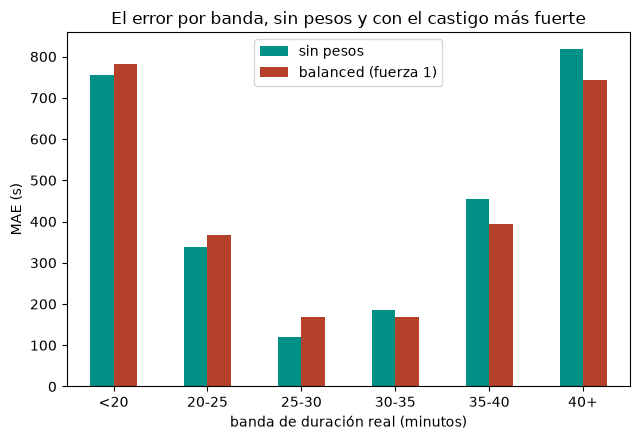

In [34]:
# Dónde gana y dónde pierde el castigo más fuerte
fig, ax = plt.subplots(figsize=(6.5, 4.5))
castigo.loc[[0.0, 1.0], ETIQUETAS].T.set_axis(["sin pesos", "balanced (fuerza 1)"], axis=1) \
    .plot(kind="bar", ax=ax, color=[TEAL, LADRILLO])
ax.set_xlabel("banda de duración real (minutos)")
ax.set_ylabel("MAE (s)")
ax.set_title("El error por banda, sin pesos y con el castigo más fuerte")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**El castigo funciona, y se cobra.** Con fuerza 1 las predicciones se abren —su
desvío pasa de 90 a 150 segundos— y las partidas de más de 40 minutos se aciertan
mejor: el error baja de 818 a 743. Pero el MAE total sube de 319,3 a **324,0**,
casi cinco segundos, alrededor de un desvío, porque las del centro empeoran: de
120 a 169 entre los 25 y los 30 minutos. Las fuerzas suaves no escapan del
intercambio. Con 0,5 el MAE ya sube 0,7 y la punta larga mejora 29.

El dato que más enseña está en la otra punta: **las partidas de menos de 20
minutos empeoran** (755 → 782) aunque también pesan más. El castigo empuja las
predicciones hacia afuera, pero el modelo sólo sabe hacia qué lado empujar
cuando tiene una pista. El elo bajo se asocia a partidas más largas, así que hay
con qué reconocer una partida larga. No hay ninguna columna que anticipe una
partida corta: una rendición a los quince minutos se decide adentro de la
partida. Abrir las predicciones ayuda de un lado y daña del otro.

Es un **intercambio**, como el `class_weight` de la Práctica 2: lo que se gana en
una banda se pierde en el total. Con el MAE declarado en la Sección 2, la
respuesta es **sin pesos**. Si algún día el uso pidiera no perderse las partidas
largas, la fuerza 1 sería la decisión correcta, y habría que declarar otra
métrica.

### 7.2 Darle forma al elo: curvas, y una pendiente por servidor

La Práctica 2 lo dijo en su Parte 5: una regresión lineal sólo puede **sumar
columnas con pesos**, así que el elo entra como una recta, «más elo, partida más
corta, siempre en la misma proporción». Si la relación tiene otra forma, la recta
no la puede dibujar, y hay que dársela hecha. Dos transformadores con la receta
de la Práctica 1:

- **`CurvasDeElo`**: reemplaza la recta por curvas suaves (`SplineTransformer`)
  sobre `elo_partida`. La cantidad de nudos es su hiperparámetro.
- **`EloPorPlataforma`**: el elo multiplicado por cada servidor, para que la
  pendiente del elo pueda ser distinta en cada uno.

In [35]:
from sklearn.preprocessing import SplineTransformer


class CurvasDeElo(BaseEstimator, TransformerMixin):
    """Agrega curvas de spline del elo de la partida: la forma que una recta no puede dibujar."""

    def __init__(self, n_knots=6):
        self.n_knots = n_knots

    def fit(self, X, y=None):
        self.spline_ = SplineTransformer(n_knots=self.n_knots).set_output(transform="pandas")
        self.spline_.fit(X[["elo_partida"]])
        return self

    def transform(self, X):
        curvas = self.spline_.transform(X[["elo_partida"]])
        curvas.index = X.index
        return pd.concat([X, curvas], axis=1)

    def get_feature_names_out(self, input_features=None):
        return np.concatenate([np.asarray(input_features), self.spline_.get_feature_names_out()])


class EloPorPlataforma(BaseEstimator, TransformerMixin):
    """Agrega el elo estandarizado multiplicado por cada plataforma: una pendiente por servidor."""

    def fit(self, X, y=None):
        self.media_, self.desvio_ = X["elo_partida"].mean(), X["elo_partida"].std()
        self.plataformas_ = sorted(X["plataforma"].unique())
        return self

    def transform(self, X):
        elo = (X["elo_partida"] - self.media_) / self.desvio_
        nuevas = pd.DataFrame({f"elo_x_{p}": elo * (X["plataforma"] == p) for p in self.plataformas_},
                              index=X.index)
        return pd.concat([X, nuevas], axis=1)

    def get_feature_names_out(self, input_features=None):
        return np.concatenate([np.asarray(input_features), [f"elo_x_{p}" for p in self.plataformas_]])


def armar_con(modelo, extras):
    """El pipeline de siempre, con pasos extra entre derivar y preparar."""
    base = armar(modelo)
    return Pipeline([("derivar", base["derivar"])] + extras
                    + [("preparar", base["preparar"]), ("modelo", modelo)])


# Que el paso nuevo no rompió nada: cuántas columnas agrega y si quedan nulos
hasta_curvas = armar_con(Ridge(), [("curvas", CurvasDeElo())])[:2].fit_transform(X_train)
pd.Series({"columnas derivadas sin curvas": armar(Ridge())["derivar"].fit_transform(X_train).shape[1],
           "con las curvas de elo": hasta_curvas.shape[1],
           "nulos": int(hasta_curvas.isna().sum().sum())})

columnas derivadas sin curvas    35
con las curvas de elo            43
nulos                             0
dtype: int64

In [36]:
# El modelo elegido con cada variante de forma, misma validación cruzada
VARIANTES_ELO = {"recta (el elegido)":           [],
                 "curvas de elo, 4 nudos":       [("curvas", CurvasDeElo(4))],
                 "curvas de elo, 6 nudos":       [("curvas", CurvasDeElo(6))],
                 "curvas de elo, 10 nudos":      [("curvas", CurvasDeElo(10))],
                 "elo × plataforma":             [("interaccion", EloPorPlataforma())],
                 "curvas (6) y elo × plataforma": [("curvas", CurvasDeElo(6)), ("interaccion", EloPorPlataforma())]}

forma_elo = pd.DataFrame({nombre: medir(armar_con(clone(elegido["modelo"]), [(n, clone(t)) for n, t in extras]))
                          for nombre, extras in VARIANTES_ELO.items()}).T[["MAE cv", "desvío", "R² cv"]]
forma_elo["mejora sobre la recta"] = forma_elo.loc["recta (el elegido)", "MAE cv"] - forma_elo["MAE cv"]
forma_elo.round(3)

,MAE cv,desvío,R² cv,mejora sobre la recta
recta (el elegido),319.342,4.476,0.051,0.000
"curvas de elo, 4 nudos",319.158,4.307,0.052,0.183
"curvas de elo, 6 nudos",319.094,4.216,0.052,0.247
"curvas de elo, 10 nudos",319.097,4.242,0.053,0.245
elo × plataforma,319.198,4.588,0.051,0.144
curvas (6) y elo × plataforma,319.139,4.293,0.052,0.202


In [37]:
# La forma que dibuja cada uno: duración media real y predicha por decil de elo, fuera de fold
pred_recta = pd.Series(cross_val_predict(clone(elegido), X_train, y_train, cv=cv, n_jobs=-1), index=X_train.index)
pred_curvas = pd.Series(cross_val_predict(armar_con(clone(elegido["modelo"]), [("curvas", CurvasDeElo(6))]),
                                          X_train, y_train, cv=cv, n_jobs=-1), index=X_train.index)
elo_train = elo_partida.loc[X_train.index]
decil = pd.qcut(elo_train, 10, labels=False)
por_decil = pd.DataFrame({"elo medio": elo_train.groupby(decil).mean(),
                          "duración real": y_train.groupby(decil).mean(),
                          "predicción de la recta": pred_recta.groupby(decil).mean(),
                          "predicción con curvas": pred_curvas.groupby(decil).mean()}).round(0)
por_decil

,elo medio,duración real,predicción de la recta,predicción con curvas
0,1337.0,1794.0,1824.0,1792.0
1,1521.0,1805.0,1801.0,1809.0
2,1752.0,1823.0,1802.0,1829.0
3,2029.0,1858.0,1826.0,1847.0
4,2398.0,1791.0,1770.0,1781.0
5,2699.0,1731.0,1733.0,1731.0
6,2927.0,1691.0,1715.0,1711.0
7,3101.0,1705.0,1706.0,1699.0
8,3265.0,1696.0,1701.0,1693.0
9,4003.0,1591.0,1606.0,1594.0


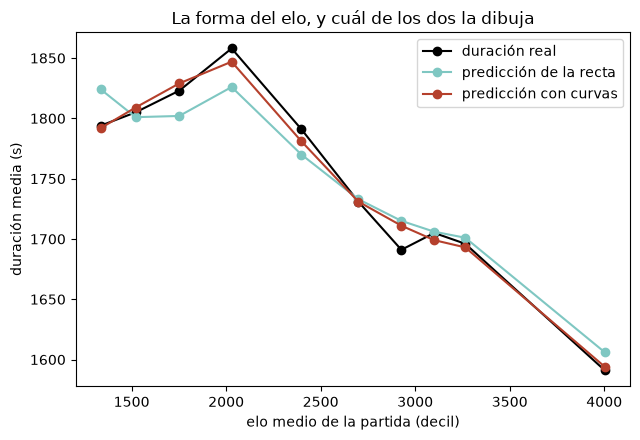

In [38]:
# Las tres líneas juntas
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(por_decil["elo medio"], por_decil["duración real"], marker="o", color="black", label="duración real")
ax.plot(por_decil["elo medio"], por_decil["predicción de la recta"], marker="o", color=TEAL_CLARO,
        label="predicción de la recta")
ax.plot(por_decil["elo medio"], por_decil["predicción con curvas"], marker="o", color=LADRILLO,
        label="predicción con curvas")
ax.set_xlabel("elo medio de la partida (decil)")
ax.set_ylabel("duración media (s)")
ax.set_title("La forma del elo, y cuál de los dos la dibuja")
ax.legend()
plt.tight_layout()
plt.show()

**La forma existe, y las curvas la dibujan.** La duración media por decil de elo
no baja en línea recta: sube de 1.794 segundos en el decil más bajo a 1.858 cerca
de elo 2.000, y recién ahí empieza a bajar, hasta 1.591 en el decil más alto. Es
una **U invertida**, y es lo que hay detrás del cambio de signo de Hierro–Oro que
aparece en la Sección 10. La recta no la puede seguir: en el primer decil predice
1.824, treinta segundos de más, y alrededor de elo 2.000 se queda corta por
treinta. Las curvas predicen 1.792 y 1.847.

**Pero la mejora en el MAE es de 0,2 segundos, con un desvío de 4,2**: no se
distingue del ruido. La cantidad de nudos no cambia nada —4, 6 y 10 dan lo mismo—
y la pendiente por servidor tampoco aporta (0,1). El motivo está en las escalas:
lo que las curvas corrigen respecto de la recta son entre veinte y treinta
segundos en algunos deciles, y la duración de cada partida se dispersa unos 420
segundos alrededor de su media. La forma es real, y pesa demasiado poco.

**Qué hago con eso. El modelo elegido no cambia.** Ninguno de los dos intentos le
gana a la recta sin pesos por más que el desvío: el castigo la empeora y las
curvas la empatan. Con la regla de la cátedra se queda el modelo de la Sección 6,
y es el que se mira en el test. Los dos intentos van a la tabla de lo que
probamos y no anduvo, cada uno con su hallazgo. El castigo muestra que **el
modelo tiene con qué reconocer una partida larga y nada con qué reconocer una
corta**. Las curvas muestran que **la relación del elo con la duración es una U
invertida con el máximo cerca de 2.000**, aunque pese demasiado poco para mover
el MAE.

# Sección 8 · El test, una sola vez

Todo lo que había que elegir —familia, hiperparámetros, columnas, y los dos
intentos de la Sección 7— ya se eligió con validación cruzada. `GridSearchCV` reentrenó el ganador sobre todo el
entrenamiento. Recién ahora se mira el test, y se mira una vez.

In [39]:
# El elegido y el piso, sobre las partidas que nadie miró hasta acá
piso_final = clone(piso).fit(X_train, y_train)
pred_test = pd.Series(elegido.predict(X_test), index=X_test.index)
pred_piso_test = pd.Series(piso_final.predict(X_test), index=X_test.index)

pd.DataFrame({"piso (mediana)": {"MAE test": mean_absolute_error(y_test, pred_piso_test),
                                 "R² test": r2_score(y_test, pred_piso_test)},
              elegido_nombre:   {"MAE test": mean_absolute_error(y_test, pred_test),
                                 "R² test": r2_score(y_test, pred_test),
                                 "MAE cv (Sección 6)": -busquedas[elegido_nombre].best_score_}}).T.round(3)

,MAE test,R² test,MAE cv (Sección 6)
piso (mediana),325.464,-0.000,NaN
regresión lineal (Ridge),315.470,0.041,319.342


In [40]:
# El mismo test, partido por grupo de elo
por_grupo_test = pd.DataFrame({"piso": mae_por_grupo(y_test, pred_piso_test, grupo_test),
                               elegido_nombre: mae_por_grupo(y_test, pred_test, grupo_test),
                               "partidas": pd.concat([grupo_test.value_counts().reindex(GRUPOS),
                                                      pd.Series({"total": len(y_test)})])})
por_grupo_test["le gana al piso por (s)"] = por_grupo_test["piso"] - por_grupo_test[elegido_nombre]
por_grupo_test["R²"] = pd.concat([
    pd.Series({g: r2_score(y_test[grupo_test == g], pred_test[grupo_test == g]) for g in GRUPOS}),
    pd.Series({"total": r2_score(y_test, pred_test)})])
por_grupo_test.round(3)

,piso,regresión lineal (Ridge),partidas,le gana al piso por (s),R²
Hierro–Oro,366.391,357.466,1312,8.925,0.020
Platino–Diamante,301.545,294.534,1122,7.010,0.027
Master–Challenger,306.210,292.811,1395,13.400,0.053
total,325.464,315.470,3829,9.994,0.041


**En el test, el modelo erra por 315,5 segundos; el piso, por 325,5.** Son 10,0
segundos de ganancia y un R² de 0,041. Coincide con la validación cruzada, que
daba 319,3: la diferencia es menor que un desvío, que es lo que tiene que pasar
cuando la búsqueda fue honesta. Y responde la sospecha de la Sección 2: si el
jugador semilla repetido de los dos lados de un corte hubiera inflado la
validación, el test habría salido peor que ella, y salió apenas mejor.

Por grupo, la ganancia sobre el piso es de **13,4 segundos en Master–Challenger**,
8,9 en Hierro–Oro y 7,0 en Platino–Diamante, con R² de 0,053, 0,020 y 0,027. El
orden entre grupos es el mismo que dio la validación cruzada.

# Sección 9 · Dónde se equivoca

Un MAE es un promedio, y un promedio esconde dónde está el error. En regresión
eso se mira de dos formas: lo real contra lo predicho, y el error partido por
tramos del objetivo. Los tramos son las bandas de minutos de la Entrega 2.

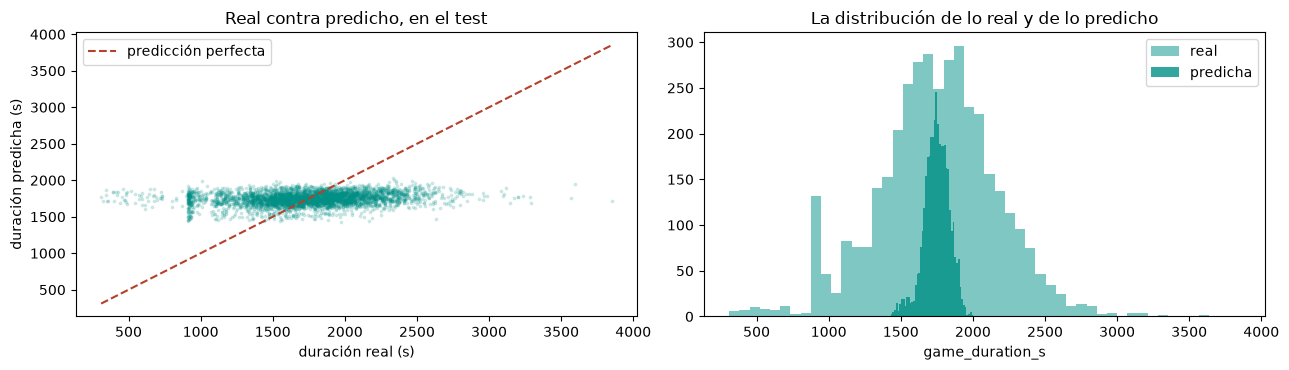

In [41]:
# Lo real contra lo predicho, y el rango de lo que el modelo se anima a contestar
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].scatter(y_test, pred_test, s=3, alpha=.15, color=TEAL)
lim = [y_test.min(), y_test.max()]
axes[0].plot(lim, lim, color=LADRILLO, linestyle="--", label="predicción perfecta")
axes[0].set_xlabel("duración real (s)")
axes[0].set_ylabel("duración predicha (s)")
axes[0].set_title("Real contra predicho, en el test")
axes[0].legend()
axes[1].hist(y_test, bins=50, color=TEAL_CLARO, label="real")
axes[1].hist(pred_test, bins=50, color=TEAL, alpha=.8, label="predicha")
axes[1].set_xlabel("game_duration_s")
axes[1].set_title("La distribución de lo real y de lo predicho")
axes[1].legend()
plt.tight_layout()
plt.show()

In [42]:
# El rango de las predicciones contra el rango de lo real
pd.DataFrame({"real": y_test.describe(), "predicha": pred_test.describe()}).round(0)

,real,predicha
count,3829.0,3829.0
mean,1746.0,1748.0
std,421.0,89.0
min,310.0,1430.0
25%,1504.0,1695.0
50%,1757.0,1750.0
75%,2010.0,1809.0
max,3850.0,2026.0


In [43]:
# El error por banda de duración: dónde erra más
banda = pd.cut(y_test / 60, bins=BANDAS, labels=ETIQUETAS)
errores = pd.DataFrame({"real": y_test, "predicha": pred_test, "banda": banda})
errores["error absoluto"] = (errores["real"] - errores["predicha"]).abs()
errores["sesgo (predicha − real)"] = errores["predicha"] - errores["real"]
errores.groupby("banda", observed=True).agg(
    partidas=("real", "size"), MAE=("error absoluto", "mean"),
    sesgo=("sesgo (predicha − real)", "mean"), predicha_media=("predicha", "mean")).round(1)

,partidas,MAE,sesgo,predicha_media
banda,,,,
<20,396,762.0,762.0,1727.7
20-25,554,341.5,341.4,1724.0
25-30,1128,117.3,86.3,1737.3
30-35,1056,184.0,-180.4,1758.0
35-40,496,456.4,-456.4,1775.8
40+,199,823.9,-823.9,1792.5


In [44]:
# El escalón de los quince minutos: las partidas que terminan por rendición apenas se habilita
rendicion = y_test.between(900, 960)
pd.Series({"partidas del test entre 900 y 960 s": int(rendicion.sum()),
           "MAE en esas partidas": mean_absolute_error(y_test[rendicion], pred_test[rendicion]),
           "predicción media en esas partidas": pred_test[rendicion].mean(),
           "MAE en el resto": mean_absolute_error(y_test[~rendicion], pred_test[~rendicion])}).round(1)

partidas del test entre 900 y 960 s     142.0
MAE en esas partidas                    782.4
predicción media en esas partidas      1707.6
MAE en el resto                         297.5
dtype: float64

**Dónde se equivoca: en las puntas.** El modelo contesta siempre cerca del medio.
Sus predicciones van de 1.430 a 2.026 segundos, con un desvío de 89, mientras que
las duraciones reales van de 310 a 3.850, con un desvío de 421. En el gráfico se
ve como una nube aplastada contra una franja horizontal.

Por banda, el error es mínimo donde vive la mayoría de las partidas —**117
segundos entre los 25 y los 30 minutos**— y crece hacia los dos lados con un
sesgo que cambia de signo. A las partidas de menos de 20 minutos las sobreestima
en 762 segundos en promedio, y a las de más de 40 las subestima en 824. Es lo que
hace un modelo con poca señal: ante la duda, contesta el centro.

**Un tramo concreto, explicado desde el juego.** Las 142 partidas del test que
terminan entre los 900 y los 960 segundos —el escalón de la rendición que encontró
la Entrega 2— se predicen en promedio en 1.708 segundos, con un error de **782**,
contra 297,5 en el resto. Ninguna columna de condiciones iniciales puede ver una
rendición: es una votación que los jugadores hacen apenas se habilita, a los
quince minutos, después de una desventaja que se armó adentro de la partida. Lo
que decide cuándo termina una partida pasa después de que empieza.

# Sección 10 · En qué se apoya

Dos lecturas, de la más pegada al modelo a la más independiente de él. Si el
elegido es lineal, sus coeficientes con su signo; y para cualquiera, la
**importancia por permutación**: se desordena una columna del test, se vuelve a
medir el MAE, y lo que empeora es lo que el modelo la necesitaba. Se permutan
las columnas **que le llegan al modelo** —sumas, diferencias, elo, plataforma—,
no las 137 crudas, porque cada derivada sale de varias crudas a la vez.

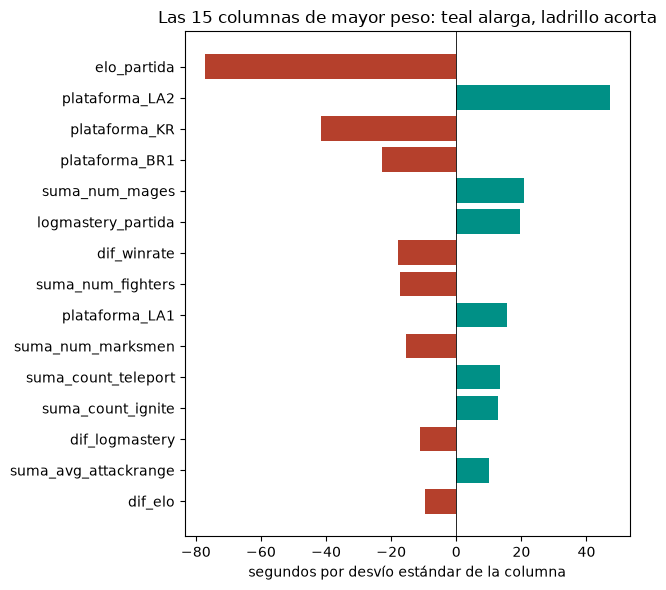

elo_partida          -77.2
plataforma_LA2        47.1
plataforma_KR        -41.5
plataforma_BR1       -22.9
suma_num_mages        20.8
logmastery_partida    19.7
dif_winrate          -18.0
suma_num_fighters    -17.3
plataforma_LA1        15.7
suma_num_marksmen    -15.5
dtype: float64

In [45]:
# Los coeficientes del modelo final, sobre columnas escaladas: comparables entre sí
nombres = [n.split("__")[-1] for n in elegido[:-1].get_feature_names_out()]
if hasattr(elegido[-1], "coef_"):
    coeficientes = pd.Series(elegido[-1].coef_, index=nombres)
    fig, ax = plt.subplots(figsize=(6.5, 6))
    top = coeficientes.reindex(coeficientes.abs().sort_values().index).tail(15)
    ax.barh(top.index, top.values, color=np.where(top.values > 0, TEAL, LADRILLO))
    ax.axvline(0, color="black", linewidth=.6)
    ax.set_title("Las 15 columnas de mayor peso: teal alarga, ladrillo acorta")
    ax.set_xlabel("segundos por desvío estándar de la columna")
    plt.tight_layout()
    plt.show()
    resultado = coeficientes.sort_values(key=abs, ascending=False).head(10).round(1)
else:
    resultado = pd.Series({"coef_": "el elegido no es lineal: se lee sólo por permutación"})
resultado

In [46]:
# Importancia por permutación, sobre el test y con la métrica declarada
Z_test = elegido["derivar"].transform(X_test)
pi = permutation_importance(elegido[1:], Z_test, y_test, scoring="neg_mean_absolute_error",
                            n_repeats=10, random_state=SEMILLA, n_jobs=-1)
importancia = pd.DataFrame({"sube el MAE (s)": pi.importances_mean, "desvío": pi.importances_std},
                           index=Z_test.columns).sort_values("sube el MAE (s)", ascending=False)
importancia.head(10).round(2)

,sube el MAE (s),desvío
elo_partida,13.35,0.77
plataforma,2.69,0.38
suma_num_fighters,0.90,0.17
suma_num_mages,0.89,0.37
dif_winrate,0.79,0.34
logmastery_partida,0.51,0.26
suma_count_ignite,0.43,0.16
dif_elo,0.39,0.16
suma_count_teleport,0.39,0.20
suma_avg_attack,0.25,0.10


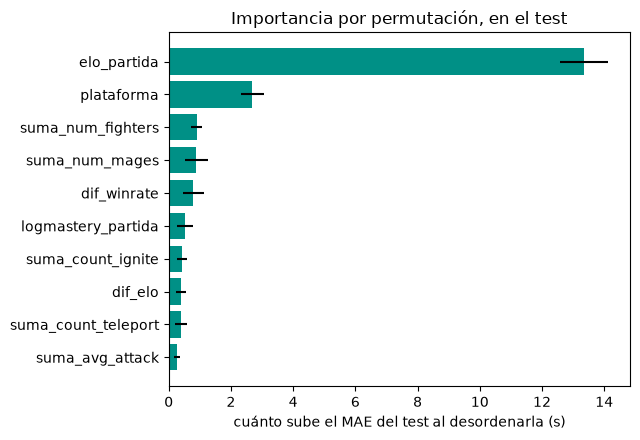

In [47]:
# Las diez columnas que más le cuestan al modelo si se vuelven ruido
fig, ax = plt.subplots(figsize=(6.5, 4.5))
top = importancia.head(10).iloc[::-1]
ax.barh(top.index, top["sube el MAE (s)"], xerr=top["desvío"], color=TEAL)
ax.set_xlabel("cuánto sube el MAE del test al desordenarla (s)")
ax.set_title("Importancia por permutación, en el test")
plt.tight_layout()
plt.show()

**El modelo se apoya en el elo, y casi en nada más.** Desordenar `elo_partida` le
sube el MAE del test **13,4 segundos**, más que toda la ganancia del modelo sobre
el piso. La sigue la plataforma, con 2,7. Del resto, ninguna columna pasa de un
segundo.

Los coeficientes cuentan lo mismo con signo. `elo_partida` pesa **−77,2 segundos
por desvío estándar**: más nivel, partida más corta, igual que H4. Las
plataformas repiten las medias por servidor de la Entrega 2: LA2 alarga (+47,1)
y KR acorta (−41,5), y LA2 era el servidor más lento y KR uno de los más rápidos.
Entre las diferencias, la que más pesa es la de winrate (−18,0, con el signo que
afirmaba H9), y su importancia por permutación es de 0,8 segundos.

In [48]:
# La columna que más pesa, mirada por grupo: el elo contra la duración dentro de cada nivel
pd.DataFrame({g: asociacion(elo_partida[grupo == g], dur[grupo == g]) for g in GRUPOS}
             | {"todas": asociacion(elo_partida, dur)}).T

,pearson,spearman,brecha
Hierro–Oro,0.042,0.035,-0.006
Platino–Diamante,-0.145,-0.150,-0.006
Master–Challenger,-0.161,-0.115,0.047
todas,-0.161,-0.155,0.006


**El chequeo de fuga de la columna que más pesa.** La pregunta es si el elo
existiría al momento de predecir. Lo que se sabe: el pipeline lee la liga de cada
jugador cuando baja la partida, no antes de que se juegue, así que el elo incluye
los puntos que el jugador ganó o perdió en esa partida y en las que jugó después.
Es un reparo real, el mismo que la Entrega 2 le marcó al winrate. **Pero no
contiene la respuesta**: ganar o perder mueve los puntos de liga igual en una
partida de 20 minutos que en una de 40, así que el elo puede tener un error de
medición y no trae la duración escrita de otra forma. Además, su peso es modesto,
un Pearson de −0,161, que explica el 2,6 % de la varianza. Nada que ver con la
columna que da demasiado bien.

La tabla de arriba agrega un matiz, y conviene decirlo antes de que lo pregunten.
La relación negativa existe en Platino–Diamante (−0,145) y en Master–Challenger
(−0,161), pero **en Hierro–Oro se da vuelta**, con +0,042. Buena parte de lo que el
modelo aprende del elo es la diferencia **entre** niveles (Hierro–Oro dura una
mediana de 1.821 segundos y Master–Challenger, 1.679) más la relación dentro de
los niveles altos. La Sección 7 mostró la forma entera, una U invertida con el
máximo cerca de elo 2.000, y mostró también que dibujarla no mejora el MAE. Por
qué las partidas más largas son las del nivel medio-bajo es una pregunta que
este notebook no contesta.

# Sección 11 · Lo que no anduvo, y lo que quedó inconcluso

### Lo que probamos y no anduvo, con su número

| Qué se probó | Qué dio | Qué se hizo |
|---|---|---|
| **H9**: las veinte diferencias entre equipos, de a una | máximo \|r\| 0,064 en total y 0,100 por grupo: rojo | hipótesis refutada |
| Las veinte diferencias, todas juntas adentro del modelo | 0,4 s de mejora en la lineal, con desvío de 4,5 | se quedan, sin defenderlas como mejora |
| La plataforma | 1,0 s de mejora, con desvío de 4,5 | se queda: es contexto conocido antes de jugar |
| Un árbol sin límite de profundidad | 467,8 s, 139 peor que el piso | limitado a profundidad 3: 322,5 |
| Bosque y boosting ajustados | 319,1 s, a 0,3 de la lineal | se queda la lineal |
| Castigar el centro con pesos por banda (`balanced`) | MAE 324,0 (+4,7); las de 40+ mejoran 75 s y las de menos de 20 empeoran 27 | sin pesos |
| Curvas de elo y una pendiente de elo por servidor | 0,2 s de mejora, con desvío de 4,2 | no entran al modelo final |

Y el resultado de fondo, que no es una falla del modelo sino del problema: **con
las condiciones iniciales, el mejor modelo le gana al piso por 10 segundos sobre
325**, un 3 %, con un R² de 0,04. Es lo que anticipó la Entrega 2 cuando ninguna
columna sola pasó del rojo contra el objetivo. Ahora se sabe que tampoco lo hacen
todas juntas, ni con la ayuda de un modelo no lineal.

### Lo que quedó inconcluso: el dataset al minuto 5 y al minuto 10

Es la segunda opción que dio el docente para el caso de que las diferencias no
funcionaran, y no funcionaron. **No se hizo en esta entrega**, y conviene decir qué
haría falta, porque no es un cambio en el notebook sino en el pipeline:

- **Un endpoint nuevo.** El estado de una partida minuto a minuto está en el
  timeline de Match-V5, que hoy `include/lol/riot.py` no consulta.
- **Una tarea nueva en el DAG**, que baje el timeline de cada partida al bronce,
  con la misma regla append-only. Es una request más por partida: unas 19.000 para
  el dataset actual, con los límites de las development keys.
- **El bronce completo**, que no está en todas las máquinas del grupo.
- **Un filtro nuevo**: una partida que termina antes del minuto de corte no tiene
  estado en ese minuto. Al minuto 10 quedan afuera todas las de menos de diez.
- **Una conversación sobre la pregunta del proyecto.** Con datos del minuto 5 o
  del 10 el modelo ya no predice desde las condiciones iniciales, sino desde el
  estado de una partida empezada. Qué variables se toman de cada minuto, y si la
  pregunta se reformula, queda por definir con el grupo.

### La limitación que declaramos

La validación se armó al azar porque el dataset no tiene fecha ni el
identificador del jugador semilla. El test salió en línea con la validación
cruzada (315,5 contra 319,3), así que no hay señales de que la repetición de
jugadores haya inflado el número, pero no se pudo descartar con `GroupKFold`.

# Cierre

In [49]:
# La tabla que resume la entrega
resumen = pd.DataFrame({n: {"MAE cv": -b.best_score_,
                            "desvío cv": b.cv_results_["std_test_score"][b.best_index_]}
                        for n, b in busquedas.items()}).T
resumen.loc["piso (mediana)"] = [tabla.loc["piso (mediana)", "MAE cv"], tabla.loc["piso (mediana)", "desvío"]]
resumen["MAE test"] = np.nan
resumen.loc[elegido_nombre, "MAE test"] = mean_absolute_error(y_test, pred_test)
resumen.loc["piso (mediana)", "MAE test"] = mean_absolute_error(y_test, pred_piso_test)
resumen.sort_values("MAE cv").round(1)

,MAE cv,desvío cv,MAE test
gradient boosting,319.1,4.3,NaN
random forest,319.1,4.5,NaN
regresión lineal (Ridge),319.3,4.5,315.5
árbol de decisión,322.5,4.0,NaN
piso (mediana),328.4,4.9,325.5


**El modelo elegido es una regresión lineal (`Ridge`, `alpha=1000`) con el
pipeline completo**, y es el que va a usar la aplicación de la Entrega 4. Predice
la duración de una partida con un error medio de **315,5 segundos en el test**,
diez menos que contestar siempre la mediana. Le gana al piso por más que el ruido
—nueve segundos en validación cruzada, dos desvíos— y no le gana por mucho: para
cualquier uso práctico, saber cuánto va a durar una partida antes de que empiece
sigue siendo casi adivinar el centro.

La respuesta honesta a la pregunta del proyecto, con lo que hay hoy en el
dataset: **las condiciones iniciales predicen muy poco de la duración**, y lo poco
que predicen lo predice sobre todo el nivel de los jugadores. Los equipos
desparejos, que era la corrección de la Entrega 2, no agregan nada. Lo que decide
cuánto dura una partida pasa adentro de ella, y es exactamente lo que mediría el
dataset al minuto 5 y al 10.